# European Greeks: Finite Differences (FDMC) vs. Malliavin vs. Fournié Localization
## Bias, Per-Path Variance, Cost per Path and Efficiency for a Call, a Digital and a Call with Terminal Knock-Out

### Overview
**Finite differences (FDMC)** re-price with bumped inputs and take difference quotients (central differences, shared random numbers, $\varepsilon = 0.01$ unless stated). They have three costs:
1. **Truncation bias** of order $\varepsilon^2$.
2. **Variance that grows as $\varepsilon \to 0$** when the payoff is not smooth: for Gamma the per-path variance grows like $1/\varepsilon$ for a kink (call) and like $1/\varepsilon^3$ for a jump (digital, knock-out).
3. **Five payoff evaluations per path** for $(\Delta, \Gamma, \mathcal{V})$: $S_0 \pm \varepsilon$, $S_0$, $\sigma \pm \varepsilon$.

**Malliavin** estimators move the derivative from the payoff onto a weight in $W_T$ (integration by parts). They are unbiased, need no bump, and use one payoff evaluation per path for all three Greeks. For smooth, unbounded payoffs their weights inflate the variance compared with the pathwise derivative.

**Fournié et al. (1999) localization** uses the Malliavin weight only near the singularities, through a cutoff $\psi$, and the pathwise derivative elsewhere.

All comparisons of accuracy are based on $R = 100$ independent runs per estimator (one `np.random.default_rng(seed)` per run) at $N \in \{10^4, 10^5, 10^6\}$, with the per-path variance stored for every run. The single-run results up to $N = 10^8$ are shown for reference.

---
## 1. Mathematical Foundations: Skorokhod Duality & Fournié Localization

### 1.1 Black-Scholes Framework & Standard Malliavin Weights
Under the risk-neutral measure $\mathbb{Q}$, the terminal spot price at maturity $T$ is:
$$S_T = S_0 \exp\left( \left(r - q - \frac{1}{2}\sigma^2\right)T + \sigma W_T \right), \quad W_T \sim \mathcal{N}(0, T)$$

Discounted option price: $V(S_0, \sigma) = e^{-rT} \mathbb{E}[\Phi(S_T)]$. Skorokhod duality yields:
$$\mathbb{E}[\langle D F, u \rangle_{L^2[0, T]}] = \mathbb{E}[F \cdot \delta(u)]$$

Standard Malliavin weights:
$$\pi^\Delta = \frac{W_T}{S_0 \sigma T} = \frac{Z}{S_0 \sigma \sqrt{T}}$$
$$\pi^\Gamma = \frac{W_T^2 - \sigma T W_T - T}{S_0^2 \sigma^2 T^2} = \frac{Z^2 - \sigma \sqrt{T} Z - 1}{S_0^2 \sigma^2 T}$$
$$\pi^{\mathcal{V}} = \frac{W_T^2 - \sigma T W_T - T}{\sigma T} = S_0^2 \sigma T \cdot \pi^\Gamma$$
where $Z = W_T / \sqrt{T} \sim \mathcal{N}(0, 1)$.

### 1.2 Fournié et al. (1999) Localized Malliavin Formulation (Theorem 2.3)
Let $\psi: \mathbb{R} \to [0, 1]$ be a smooth $C^1$ cutoff function centered at the strike $K$ with half-width $\delta$:
$$\psi(S_T) \approx 1 \text{ for } |S_T - K| < \delta, \qquad \psi(S_T) \approx 0 \text{ for } |S_T - K| \ge \delta$$

Applying the product rule and Skorokhod integration by parts only to $\Phi(S_T) \psi(S_T)$ while using the pathwise derivative for $\Phi(S_T)(1 - \psi(S_T))$ yields the exact localized estimators:

1. **Localized Delta ($\Delta_{\text{loc}}$)**:
   $$\Delta_{\text{loc}} = e^{-rT} \mathbb{E}\left[ \Phi(S_T) \left(\psi(S_T) \pi^\Delta - \psi'(S_T) \frac{S_T}{S_0}\right) + \Phi'(S_T) (1 - \psi(S_T)) \frac{S_T}{S_0} \right]$$

2. **Localized Vega ($\mathcal{V}_{\text{loc}}$)**:
   $$\mathcal{V}_{\text{loc}} = e^{-rT} \mathbb{E}\left[ \Phi(S_T) \left(\psi(S_T) \pi^{\mathcal{V}} - \psi'(S_T) S_T (W_T - \sigma T)\right) + \Phi'(S_T) (1 - \psi(S_T)) S_T (W_T - \sigma T) \right]$$

3. **Localized Gamma ($\Gamma_{\text{loc}}$)**, general formula for any payoff:
   $$\Gamma_{\text{loc}} = e^{-rT} \mathbb{E}\left[ \Phi\,\psi\,\pi^\Gamma + \Big(\Phi''(1 - \psi) - 2\Phi'\psi' - \Phi\psi''\Big)\left(\frac{S_T}{S_0}\right)^2 \right]$$
   $\Phi'$ and $\Phi''$ are the classical (almost-everywhere) derivatives. The Dirac masses of the distributional derivatives sit at the singularities, where $\psi = 1$ and $\psi' = 0$, so they drop out. For the call with terminal knock-out the cutoff must satisfy this at both $K$ and $H$: $\psi = 1 - (1-\psi_K)(1-\psi_H)$ does, $\psi_K + \psi_H$ does not for the Gaussian cutoff (Section 5).
   *(The earlier call-only shortcut $\Gamma_{\text{call}} = (K/S_0)\,\Delta^{\text{loc}}_{\text{digital}}$ is kept as a separate run, "Malliavin Fournié (Γ shortcut)", for comparison.)*

### 1.3 Supported Smoothing Functions $\psi(S_T)$
With normalized distance $u = |S_T - K| / \delta$:
- **Gaussian (Default & Optimal)**: $\psi(S_T) = \exp(-0.5 u^2)$, $\quad \psi'(S_T) = -\frac{S_T - K}{\delta^2} \psi(S_T)$
- **Compact Cubic Hermite**: $\psi(S_T) = 1 - 3u^2 + 2u^3$ for $u \le 1$, $0$ otherwise.
- **Compact Cosine**: $\psi(S_T) = \frac{1}{2}(1 + \cos(\pi u))$ for $u \le 1$, $0$ otherwise.
- **Compact Quintic**: $\psi(S_T) = 1 - 10u^3 + 15u^4 - 6u^5$ for $u \le 1$, $0$ otherwise.
- **Rational Cauchy**: $\psi(S_T) = \frac{1}{1 + u^2}$, $\quad \psi'(S_T) = -\frac{2(S_T - K)}{\delta^2 (1 + u^2)^2}$

### 1.4 Option A: Decoupled Bandwidths per Greek ($\delta_\Delta \ne \delta_\Gamma \ne \delta_\mathcal{V}$)
A critical insight established in our dedicated gap analysis is that **the optimal Fournié smoothing bandwidth depends directly on the singularity order of each Greek**:
- **Delta ($\Delta$) and Vega ($\mathcal{V}$): Continuous Kink ($C^0$)**
  The payoff $g(S_T) = (S_T - K)^+$ is continuous. As $S_T \to K$, $g(S_T) \to 0$, which naturally suppresses the boundary derivative spike $-\psi'(S_T) \sim 1/\delta$. Therefore, Delta and Vega achieve minimal variance with a narrower bandwidth that maximizes the domain of the pathwise derivative:
  $$\delta^*_\Delta = \delta^*_\mathcal{V} \approx 0.20 \times S_0 \sigma \sqrt{T} = 4.0 \quad (T = 1.0)$$
- **Gamma ($\Gamma$): Discontinuous Step ($C^{-1}$)**
  Gamma differentiates the digital step indicator $g'(S_T) = \mathbf{1}_{S_T > K}$, which jumps by $+1$ at $K$. The boundary term $-\psi'(S_T) \frac{S_T}{S_0}$ has no $(S_T - K)$ dampener and blows up as $\mathcal{O}(1/\delta)$ if $\delta$ is too small. Hence, Gamma strictly requires a wider bandwidth:
  $$\delta^*_\Gamma \approx 0.50 \times S_0 \sigma \sqrt{T} = 10.0 \quad (T = 1.0)$$

**Option A vs. Option B:**
Rather than one compromise bandwidth for all Greeks (Option B, e.g. $\delta = 8.0$), **Option A uses one bandwidth per Greek** in the same Monte Carlo pass. Section 7 measures the difference.

In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import Utilities as utils
from products import (
    example_european_call_ATM,
    example_european_digital_ATM,
    example_european_call_terminal_knockout,
)

pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", 16)
pd.set_option("display.width", 1000)

print("Environment and Utilities loaded successfully.")

Environment and Utilities loaded successfully.


---
## 2. Data

1. **Analytical benchmarks**: Black-Scholes closed forms (QuantLib for the digital). The call with terminal knock-out is two calls and a digital: $(S_T-K)^+ - (S_T-H)^+ - (H-K)\mathbf{1}_{S_T>H}$.
2. **Single-run sweeps** (`FDMC_results.csv`, `malliavin_results.csv`, `malliavin_fournier_results.csv`): one seed, $N$ from $10^4$ to $10^8$, with the per-path variance and standard error of every Greek.
3. **Replications** (`replications_summary.csv`, `efficiency.csv`): $R = 100$ seeds at $N \in \{10^4, 10^5, 10^6\}$, with bias, RMSE, coverage, per-path variance and time per path.

Fournié settings: Gaussian cutoff, bandwidths $\delta_\Delta = \delta_\mathcal{V} = 4$, $\delta_\Gamma = 10$ for the call and the digital, and $\delta = (H-K)/2 = 2.625$ for the knock-out with $\psi = 1 - (1-\psi_K)(1-\psi_H)$.

In [2]:
benchmarks_df, fdmc_df, malliavin_df, malliavin_fournier_df = utils.load_all_simulation_results()
fdmc_metrics_df = utils.compute_error_metrics(fdmc_df, benchmarks_df)
mal_metrics_df = utils.compute_error_metrics(malliavin_df, benchmarks_df)
four_metrics_df = utils.compute_error_metrics(malliavin_fournier_df, benchmarks_df)

print("=== Exact Analytical Benchmark Reference Values ===")
display(benchmarks_df.set_index("Product"))

# Independent replications (run_replications.py): R seeds per (estimator, product, N)
rep_summary = pd.read_csv("./results/replications_summary.csv")
efficiency_df = pd.read_csv("./results/efficiency.csv")

=== Exact Analytical Benchmark Reference Values ===


,delta,gamma,vega,Method
Product,,,,
Call European ATM,0.586851,0.018951,37.901158,Analytical
Digital European ATM,0.018951,-0.000237,-0.473764,Analytical
Call with terminal knock-out,0.001509,-0.000630,-1.259414,Analytical


### 2.1 Single Run at $N = 10^8$

Absolute errors of one run at $N = 10^8$, FDMC at the fixed production step $\varepsilon = 0.01$ (in practice the analytical value is unknown, so $\varepsilon$ cannot be tuned per Greek after the fact). A single run's error is one draw of a random variable whose size is about one standard error, so ratios of these errors between methods are noisy. Use the replications and the per-path variances (Section 6) for comparisons.

In [3]:
comp_summary = utils.compute_comparative_summary_table(
    fdmc_metrics_df, mal_metrics_df, n_choice=100_000_000,
    criterion="abs_error", fournier_metrics_df=four_metrics_df
)
display(comp_summary)

,Product,Greek,Benchmark,FDMC (ε=0.01),FDMC ε,FDMC Abs Error,Std Malliavin,Std Mal Abs Error,...,Std Mal Rel Err (%),Accuracy Ratio (FDMC/Mal),Ratio (FDMC/Std Mal),Fournié Malliavin,Fournié Abs Error,Fournié Rel Err (%),Ratio (FDMC/Fournié),Fournié Gain vs Std
0,Call European ATM,delta,0.586851,0.586811,0.01,0.000040,0.586883,3.229801e-05,...,0.005504,1.252611e+00,1.252611e+00,0.586814,3.686961e-05,0.006283,1.097295,0.876006
1,Call European ATM,gamma,0.018951,0.019010,0.01,0.000059,0.018953,2.262019e-06,...,0.011936,2.609489e+01,2.609489e+01,0.018947,4.011989e-06,0.021171,14.712686,0.563815
2,Call European ATM,vega,37.901158,37.901434,0.01,0.000277,37.905682,4.524039e-03,...,0.011936,6.121784e-02,6.121784e-02,37.902557,1.399730e-03,0.003693,0.197861,3.232079
3,Digital European ATM,delta,0.018951,0.018948,0.01,0.000002,0.018951,3.211787e-08,...,0.000169,6.502981e+01,6.502981e+01,0.018949,1.117412e-06,0.005896,1.869157,0.028743
4,Digital European ATM,gamma,-0.000237,0.001902,0.01,0.002139,-0.000237,1.692774e-07,...,0.071461,1.263808e+04,1.263808e+04,-0.000237,2.330083e-07,0.098365,9181.392517,0.726486
5,Digital European ATM,vega,-0.473764,-0.474539,0.01,0.000774,-0.473426,3.385548e-04,...,0.071461,2.287378e+00,2.287378e+00,-0.473718,4.652655e-05,0.009821,16.644323,7.276593
6,Call with terminal knock-out,delta,0.001509,0.001662,0.01,0.000152,0.001509,7.757698e-08,...,0.005140,1.963184e+03,1.963184e+03,0.001505,4.496601e-06,0.297937,33.869550,0.017252
7,Call with terminal knock-out,gamma,-0.000630,-0.105873,0.01,0.105243,-0.000630,8.051817e-09,...,0.001279,1.307072e+07,1.307072e+07,-0.000636,6.558898e-06,1.041579,16045.847763,0.001228
8,Call with terminal knock-out,vega,-1.259414,-1.262345,0.01,0.002930,-1.259430,1.610363e-05,...,0.001279,1.819750e+02,1.819750e+02,-1.259360,5.391255e-05,0.004281,54.355795,0.298699


---
## 3. Deep Dive: Vanilla European Call (Smooth Payoff)

### The Variance Challenge Solved:
For smooth payoffs, standard Malliavin integration by parts uses quadratic polynomial weights in $W_T$, which introduces higher sample variance than the pathwise derivative.
The error plots below come from $R = 100$ independent runs (one `np.random.default_rng(seed)` per run) at $N \in \{10^4, 10^5, 10^6\}$:
- **Solid line**: RMSE against the analytical value over the $R$ runs.
- **Band**: 10th–90th percentile of $|\hat\theta - \theta|$ across runs.
- **Dashed line**: extrapolation $\sqrt{\text{bias}^2 + \text{Var}/N}$ to $N = 10^8$, using the measured per-path variance (the bias term is kept only when significant, e.g. FDMC truncation bias).
- **FDMC** uses the fixed production step $\varepsilon = 0.01$; the Fournié Gamma uses the general localized formula, with the old call-only shortcut shown dotted.

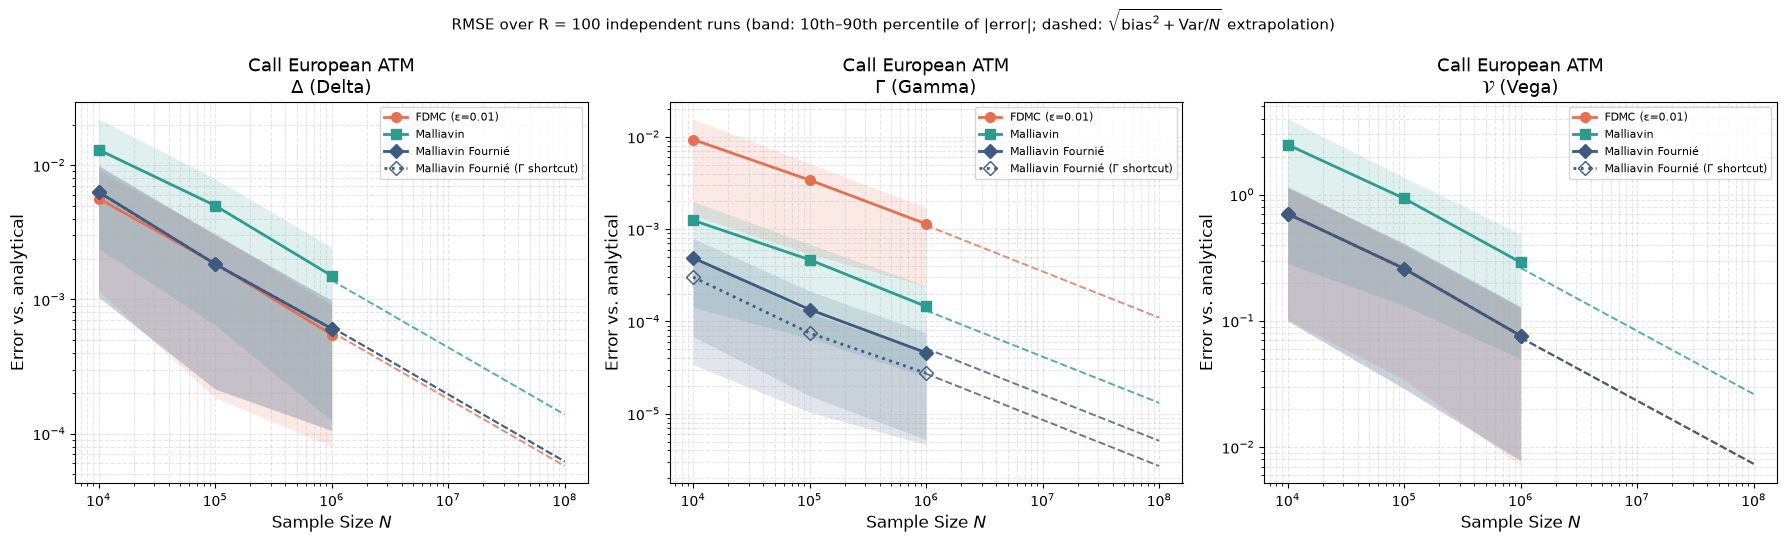

In [4]:
fig_call_conv = utils.plot_replication_error_vs_N(rep_summary, "Call European ATM")
plt.show()

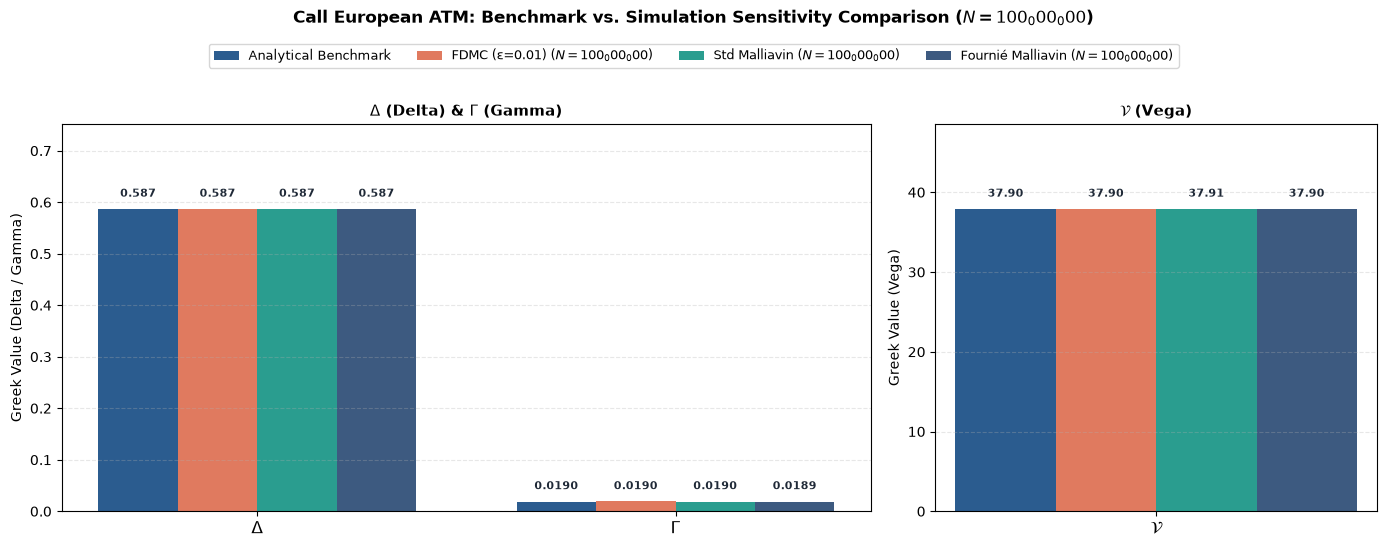

In [5]:
fig_call_bars = utils.plot_comparative_greeks_bars(
    fdmc_metrics_df, mal_metrics_df, "Call European ATM",
    n_choice=100_000_000, fournier_metrics_df=four_metrics_df
)
plt.show()

---
## 4. Deep Dive: Digital European Call (Discontinuous Step Payoff)

### The Structural Failure of Finite Differences on Indicator Payoffs:
The digital call pays $\\mathbf{1}_{S_T > K}$. The derivative is a Dirac delta measure $\\delta(S_T - K)$.
- In FDMC, central differences divide by $\\varepsilon$ or $\\varepsilon^2$ across a step discontinuity. If $\\varepsilon$ is too small, no paths cross $[K-\\varepsilon, K+\\varepsilon]$, leading to complete estimator collapse. If $\\varepsilon$ is large, bias $\\mathcal{O}(\\varepsilon^2)$ is unacceptably high.
- **Malliavin calculus transfers the derivative to smooth Gaussian weights**, so its variance does not depend on any step size.
- At $\varepsilon = 0.01$ the per-path variance of the FDMC digital Gamma is about $3.6 \times 10^{4}$, against about $5 \times 10^{-6}$ for standard Malliavin (`efficiency.csv`).

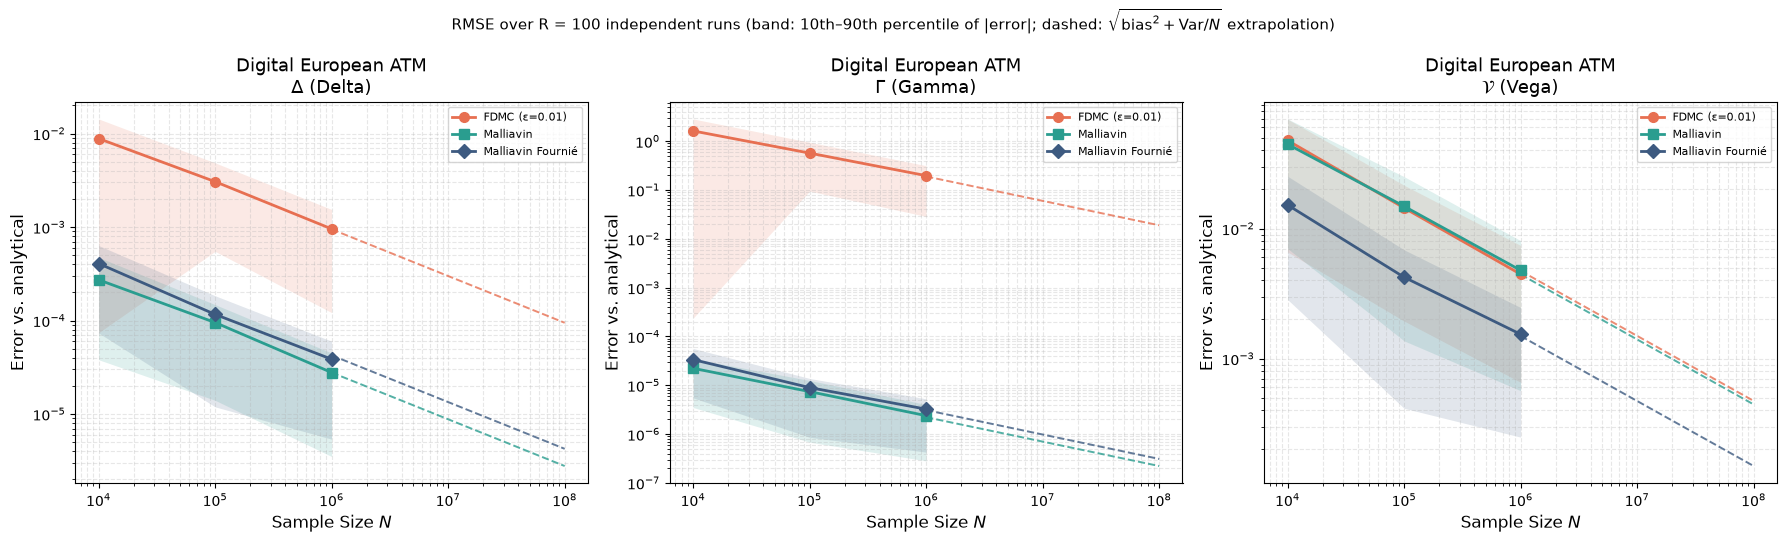

In [6]:
fig_dig_conv = utils.plot_replication_error_vs_N(rep_summary, "Digital European ATM")
plt.show()

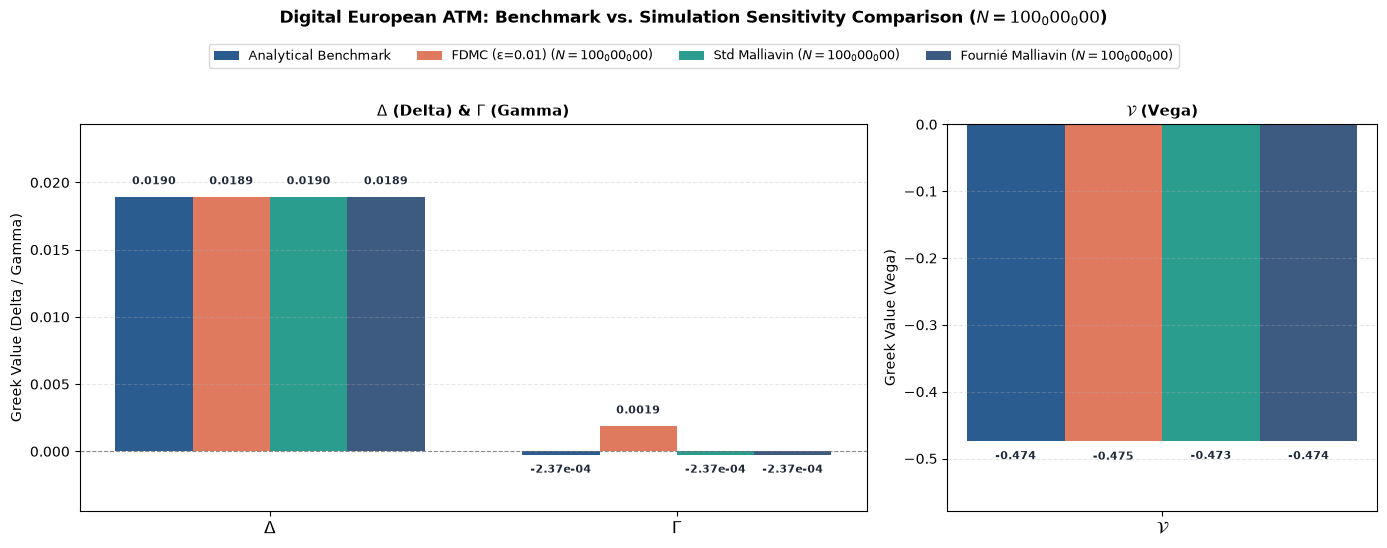

=== Digital Call Gamma: Malliavin Convergence to Analytical Benchmark ===


,N,Std Malliavin Gamma,Std Mal Abs Error,Benchmark
1,10000,-0.000219,1.812205e-05,-0.000237
4,100000,-0.000240,2.823516e-06,-0.000237
7,250000,-0.000240,3.082064e-06,-0.000237
10,1000000,-0.000239,1.680116e-06,-0.000237
13,2000000,-0.000238,1.378184e-06,-0.000237
16,5000000,-0.000237,5.632689e-07,-0.000237
19,10000000,-0.000237,1.375917e-07,-0.000237
22,30000000,-0.000237,3.334896e-07,-0.000237
25,50000000,-0.000237,2.947394e-08,-0.000237
28,100000000,-0.000237,1.692774e-07,-0.000237


In [7]:
fig_dig_bars = utils.plot_comparative_greeks_bars(
    fdmc_metrics_df, mal_metrics_df, "Digital European ATM",
    n_choice=100_000_000, fournier_metrics_df=four_metrics_df
)
plt.show()

# Digital Gamma convergence inspection
dig_bench = benchmarks_df[benchmarks_df["Product"] == "Digital European ATM"]["gamma"].values[0]
dig_mal_gamma = mal_metrics_df[mal_metrics_df["Product"] == "Digital European ATM"][["N", "gamma", "gamma_abs_error"]].copy()
dig_mal_gamma.columns = ["N", "Std Malliavin Gamma", "Std Mal Abs Error"]
dig_mal_gamma["Benchmark"] = dig_bench

print("=== Digital Call Gamma: Malliavin Convergence to Analytical Benchmark ===")
display(dig_mal_gamma)

---
## 5. Deep Dive: Call with Terminal Knock-Out

Payoff $(S_T - K)^+ \mathbf{1}_{S_T \le H}$, checked at maturity only (not a path-dependent barrier).

### Jump Discontinuity at $H = 105.25$:
Differentiating across the barrier creates a negative Dirac jump $-(H - K) \\delta(S_T - H)$.
- FDMC divides a jump of size $H - K$ by $\varepsilon^2$, so its Gamma has a per-path variance of about $10^{6}$ at $\varepsilon = 0.01$.
- Standard Malliavin has a per-path Gamma variance of about $5 \times 10^{-6}$: about $90\%$ of paths end outside $[K, H]$, where the payoff and the sample are zero.
- Fournié with the unbiased cutoff is unbiased but has a larger variance than standard Malliavin for Delta and Gamma. Fournié with $\psi_K + \psi_H$ (dotted line) is biased: its error stops decreasing with $N$.

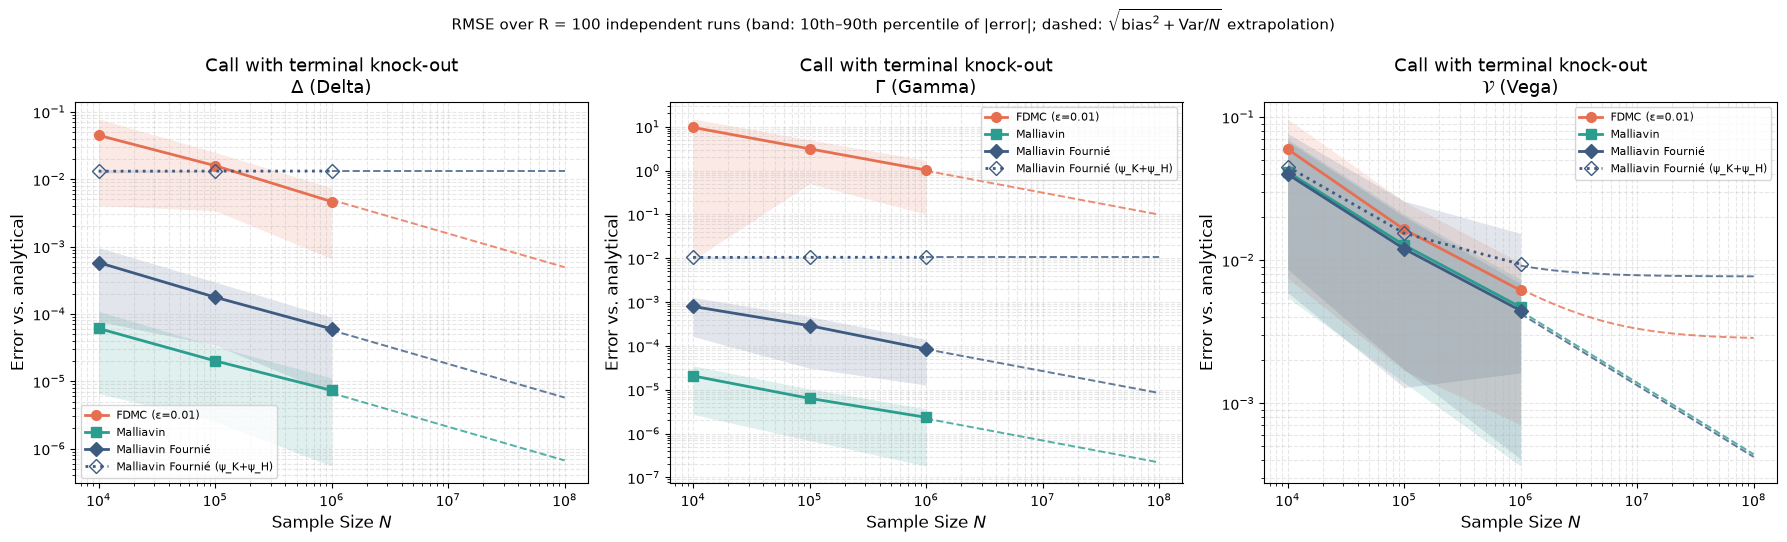

In [8]:
fig_bar_conv = utils.plot_replication_error_vs_N(rep_summary, "Call with terminal knock-out")
plt.show()

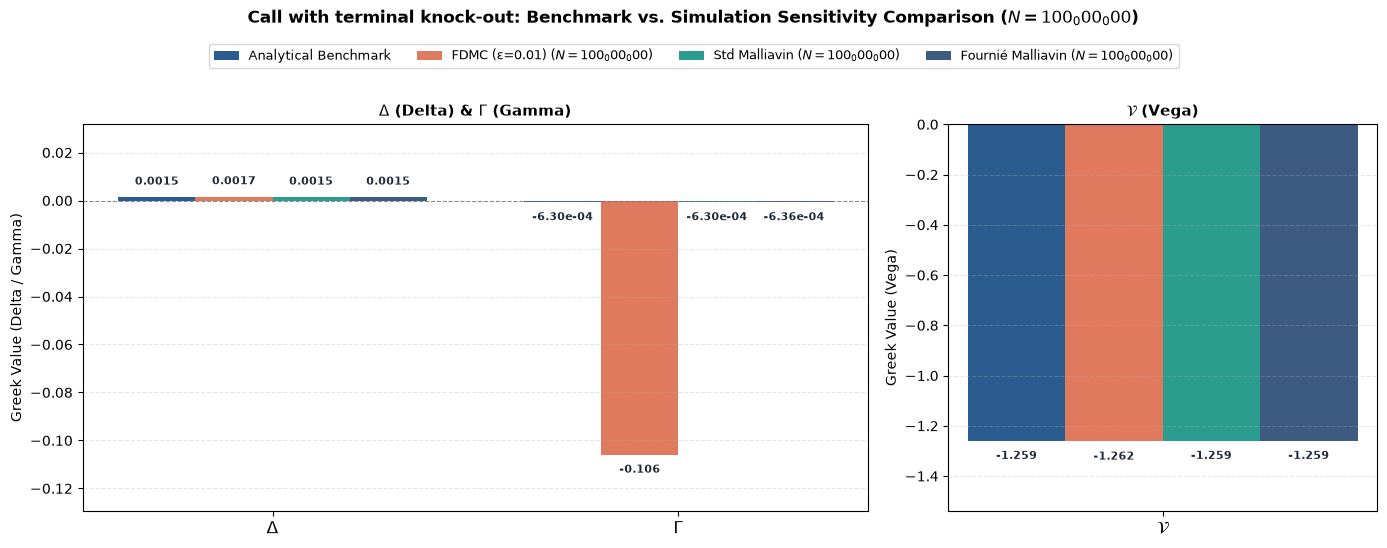

In [9]:
fig_bar_bars = utils.plot_comparative_greeks_bars(
    fdmc_metrics_df, mal_metrics_df, "Call with terminal knock-out",
    n_choice=100_000_000, fournier_metrics_df=four_metrics_df
)
plt.show()

---
## 6. Per-Path Variance, Time per Path and Efficiency

Every estimator is a mean of i.i.d. per-path quantities, so for a tolerance $\text{tol}$ at confidence $z$ the required number of paths is
$$N^* = \frac{z^2\,\text{Var}}{\text{tol}^2}, \qquad \frac{N^*_{\text{Malliavin}}}{N^*_{\text{FDMC}}} = \frac{\text{Var}_{\text{Malliavin}}}{\text{Var}_{\text{FDMC}}}.$$
All three Greeks are timed together per method (FDMC: 5 payoff evaluations per path; standard Malliavin: 1; Fournié: 1 plus the cutoff evaluations). Efficiency is $\text{Var} \times \text{time per path}$, the CPU time needed per unit of inverse squared error (lower is better).
- `n_ratio_vs_FDMC`: paths needed relative to FDMC ($\varepsilon = 0.01$) for the same SE.
- `efficiency_ratio_vs_FDMC`: CPU time relative to FDMC for the same SE.
- `n_star`, `time_star_s`: paths and seconds for a 95% half-width of 1% of the analytical value. They ignore bias; `bias_exceeds_tol` flags FDMC rows where the truncation bias alone exceeds that tolerance.

In [10]:
display(efficiency_df)

,Product,Greek,Estimator,Method,eps,N,benchmark,bias,...,time_per_path_ns,efficiency,n_ratio_vs_FDMC,efficiency_ratio_vs_FDMC,tol,n_star,time_star_s,bias_exceeds_tol
0,Call European ATM,delta,FDMC (ε=0.1),FDMC,0.100,1000000,0.586851,-1.352580e-05,...,72.010541,2.366709e-08,9.983562e-01,9.650609e-01,0.005869,3.666106e+04,2.639983e-03,False
1,Call European ATM,delta,FDMC (ε=0.001),FDMC,0.001,1000000,0.586851,-1.026049e-05,...,74.461645,2.451698e-08,1.000164e+00,9.997166e-01,0.005869,3.672744e+04,2.734786e-03,False
2,Call European ATM,delta,FDMC (ε=0.01),FDMC,0.010,1000000,0.586851,-1.036714e-05,...,74.494959,2.452393e-08,1.000000e+00,1.000000e+00,0.005869,3.672142e+04,2.735561e-03,False
3,Call European ATM,delta,Malliavin Fournié (Γ shortcut),Malliavin Fournié (Γ shortcut),NaN,1000000,0.586851,3.905422e-06,...,74.885667,2.881092e-08,1.168679e+00,1.174808e+00,0.005869,4.291554e+04,3.213759e-03,False
4,Call European ATM,delta,Malliavin Fournié,Malliavin Fournié,NaN,1000000,0.586851,3.905422e-06,...,77.085958,2.965744e-08,1.168679e+00,1.209326e+00,0.005869,4.291554e+04,3.308186e-03,False
5,Call European ATM,delta,Malliavin,Malliavin,NaN,1000000,0.586851,9.822991e-05,...,27.452416,5.289008e-08,5.852351e+00,2.156672e+00,0.005869,2.149066e+05,5.899707e-03,False
6,Call European ATM,gamma,Malliavin Fournié (Γ shortcut),Malliavin Fournié (Γ shortcut),NaN,1000000,0.018951,-2.556753e-07,...,74.885667,5.518938e-11,6.104390e-04,6.136406e-04,0.000190,7.883590e+04,5.903679e-03,False
7,Call European ATM,gamma,Malliavin Fournié,Malliavin Fournié,NaN,1000000,0.018951,-1.959008e-06,...,77.085958,1.999364e-10,2.148335e-03,2.223056e-03,0.000190,2.774494e+05,2.138745e-02,False
8,Call European ATM,gamma,Malliavin,Malliavin,NaN,1000000,0.018951,1.675635e-05,...,27.452416,4.726582e-10,1.426107e-02,5.255400e-03,0.000190,1.841763e+06,5.056086e-02,False
9,Call European ATM,gamma,FDMC (ε=0.1),FDMC,0.100,1000000,0.018951,1.915149e-05,...,72.010541,8.633204e-09,9.930276e-02,9.599100e-02,0.000190,1.282458e+07,9.235048e-01,False


---
## 7. Fournié Localized Malliavin: Empirical Variance Reduction & Decoupled Bandwidths (Option A)

### Direct Variance Measurement: Standard vs. Coupled Fournié vs. Option A Decoupled
We execute 100 independent Monte Carlo runs of $N = 10,000$ simulations to directly measure the sample variance of the estimators:
$$\text{Var}(\hat{\theta}) = \frac{1}{M-1} \sum_{m=1}^M (\hat{\theta}_m - \bar{\theta})^2$$

We compare:
1. **Standard Malliavin**: Pure Skorokhod duality with polynomial weights.
2. **Coupled Fournié ($\delta = 8.0$)**: Uniform compromise bandwidth.
3. **Option A Decoupled Fournié**: $\delta^*_\Delta = 4.0$, $\delta^*_\Gamma = 10.0$, $\delta^*_\mathcal{V} = 4.0$ tailored to each Greek's singularity order.

In [11]:
from Methods.Malliavin.malliavin_european_standard import malliavin_greeks_european_call, generate_paths
from Methods.Malliavin.malliavin_european_fournier import malliavin_fournier_greeks_european_call

params = example_european_call_ATM
n_runs = 100
n_sims = 10000

std_deltas, std_gammas, std_vegas = [], [], []
coup_deltas, coup_gammas, coup_vegas = [], [], []
decoup_deltas, decoup_gammas, decoup_vegas = [], [], []

decoupled_deltas = {"delta": 4.0, "gamma": 10.0, "vega": 4.0}

for s in range(n_runs):
    paths = generate_paths(params["T"], n_sims, seed=s)
    r_std = malliavin_greeks_european_call(params, N=n_sims, paths=paths)
    r_coup = malliavin_fournier_greeks_european_call(params, N=n_sims, paths=paths, cutoff_type="gaussian", bandwidth=8.0)
    r_decoup = malliavin_fournier_greeks_european_call(params, N=n_sims, paths=paths, cutoff_type="gaussian", bandwidth=decoupled_deltas)
    
    std_deltas.append(r_std["delta"])
    std_gammas.append(r_std["gamma"])
    std_vegas.append(r_std["vega"])
    
    coup_deltas.append(r_coup["delta"])
    coup_gammas.append(r_coup["gamma"])
    coup_vegas.append(r_coup["vega"])
    
    decoup_deltas.append(r_decoup["delta"])
    decoup_gammas.append(r_decoup["gamma"])
    decoup_vegas.append(r_decoup["vega"])

var_std_d, var_std_g, var_std_v = float(np.var(std_deltas)), float(np.var(std_gammas)), float(np.var(std_vegas))
var_coup_d, var_coup_g, var_coup_v = float(np.var(coup_deltas)), float(np.var(coup_gammas)), float(np.var(coup_vegas))
var_decoup_d, var_decoup_g, var_decoup_v = float(np.var(decoup_deltas)), float(np.var(decoup_gammas)), float(np.var(decoup_vegas))

var_df = pd.DataFrame([
    {
        "Greek": "Delta (Δ)",
        "Std Malliavin Var": var_std_d,
        "Coupled Fournié (δ=8) Var": var_coup_d,
        "Option A Decoupled Var": var_decoup_d,
        "Redux vs Std (Coupled)": f"{var_std_d/var_coup_d:.2f}x",
        "Redux vs Std (Option A)": f"{var_std_d/var_decoup_d:.2f}x",
        "Option A Gain vs Coupled": f"+{(var_coup_d/var_decoup_d - 1)*100:.1f}%",
    },
    {
        "Greek": "Gamma (Γ)",
        "Std Malliavin Var": var_std_g,
        "Coupled Fournié (δ=8) Var": var_coup_g,
        "Option A Decoupled Var": var_decoup_g,
        "Redux vs Std (Coupled)": f"{var_std_g/var_coup_g:.2f}x",
        "Redux vs Std (Option A)": f"{var_std_g/var_decoup_g:.2f}x",
        "Option A Gain vs Coupled": f"+{(var_coup_g/var_decoup_g - 1)*100:.1f}%",
    },
    {
        "Greek": "Vega (V)",
        "Std Malliavin Var": var_std_v,
        "Coupled Fournié (δ=8) Var": var_coup_v,
        "Option A Decoupled Var": var_decoup_v,
        "Redux vs Std (Coupled)": f"{var_std_v/var_coup_v:.2f}x",
        "Redux vs Std (Option A)": f"{var_std_v/var_decoup_v:.2f}x",
        "Option A Gain vs Coupled": f"+{(var_coup_v/var_decoup_v - 1)*100:.1f}%",
    },
])
print("=== Empirical Variance Reduction: Standard vs. Coupled Fournié vs. Option A Decoupled ===")
display(var_df)

=== Empirical Variance Reduction: Standard vs. Coupled Fournié vs. Option A Decoupled ===


,Greek,Std Malliavin Var,Coupled Fournié (δ=8) Var,Option A Decoupled Var,Redux vs Std (Coupled),Redux vs Std (Option A),Option A Gain vs Coupled
0,Delta (Δ),0.000205,4.834232e-05,4.299407e-05,4.24x,4.77x,+12.4%
1,Gamma (Γ),0.000002,3.186155e-07,2.239694e-07,5.88x,8.36x,+42.3%
2,Vega (V),7.490219,5.867749e-01,5.624529e-01,12.77x,13.32x,+4.3%


---
## 8. Fixed Time Budgets

Given a CPU budget $B$ and the measured time per path $t$ (all three Greeks together), an estimator gets $N = B / t$ paths and its expected error is
$$\text{RMSE}(B) = \sqrt{\text{bias}^2 + \text{Var}\cdot t / B}.$$
The bias term is kept only when it is significant in the replications. The table gives the expected RMSE for budgets of 250 ms, 1 s and 5 s. It replaces the earlier budget and Pareto charts, which were built from the error of a single run at each $N$.

In [12]:
budget_df = utils.expected_error_under_budget(efficiency_df, budgets_ms=[250.0, 1000.0, 5000.0])
budget_df = budget_df[~budget_df["Estimator"].isin(["FDMC (ε=0.1)", "FDMC (ε=0.001)"])]
display(budget_df.pivot_table(index=["Product", "Greek", "Estimator"], columns="budget_ms", values="expected_rmse"))

budget_ms                                                                250.0         1000.0        5000.0
Product                      Greek Estimator                                                               
Call European ATM            delta FDMC (ε=0.01)                   3.132024e-04  1.566012e-04  7.003418e-05
                                   Malliavin                       4.599569e-04  2.299784e-04  1.028495e-04
                                   Malliavin Fournié               3.444267e-04  1.722134e-04  7.701615e-05
                                   Malliavin Fournié (Γ shortcut)  3.394756e-04  1.697378e-04  7.590905e-05
                             gamma FDMC (ε=0.01)                   5.997921e-04  2.998960e-04  1.341176e-04
                                   Malliavin                       4.348141e-05  2.174070e-05  9.722739e-06
                                   Malliavin Fournié               2.827977e-05  1.413989e-05  6.323550e-06
                                   Malliavin Fournié (Γ shortcut)  1.485791e-05  7.428956e-06  3.322330e-06
                             vega  FDMC (ε=0.01)                   4.007869e-02  2.003934e-02  8.961867e-03
                                   Malliavin                       8.696282e-02  4.348141e-02  1.944548e-02
                                   Malliavin Fournié               4.082534e-02  2.041267e-02  9.128824e-03
                                   Malliavin Fournié (Γ shortcut)  4.023848e-02  2.011924e-02  8.997597e-03
Call with terminal knock-out delta FDMC (ε=0.01)                   2.793303e-03  1.396652e-03  6.246016e-04
                                   Malliavin                       2.229144e-06  1.114572e-06  4.984518e-07
                                   Malliavin Fournié               3.214566e-05  1.607283e-05  7.187987e-06
                                   Malliavin Fournié (ψ_K+ψ_H)     1.319463e-02  1.319459e-02  1.319459e-02
                             gamma FDMC (ε=0.01)                   5.586717e-01  2.793358e-01  1.249228e-01
                                   Malliavin                       7.345381e-07  3.672691e-07  1.642477e-07
                                   Malliavin Fournié               4.729374e-05  2.364687e-05  1.057520e-05
                                   Malliavin Fournié (ψ_K+ψ_H)     1.049924e-02  1.049919e-02  1.049918e-02
                             vega  FDMC (ε=0.01)                   4.242547e-03  3.224656e-03  2.893359e-03
                                   Malliavin                       1.469076e-03  7.345381e-04  3.284954e-04
                                   Malliavin Fournié               2.366928e-03  1.183464e-03  5.292612e-04
                                   Malliavin Fournié (ψ_K+ψ_H)     8.132373e-03  7.798464e-03  7.706979e-03
Digital European ATM         delta FDMC (ε=0.01)                   5.103643e-04  2.551821e-04  1.141209e-04
                                   Malliavin                       9.129175e-06  4.564587e-06  2.041346e-06
                                   Malliavin Fournié               2.329522e-05  1.164761e-05  5.208970e-06
                             gamma FDMC (ε=0.01)                   1.020931e-01  5.104654e-02  2.282871e-02
                                   Malliavin                       7.291521e-07  3.645761e-07  1.630434e-07
                                   Malliavin Fournié               1.702191e-06  8.510953e-07  3.806214e-07
                             vega  FDMC (ε=0.01)                   2.548729e-03  1.274364e-03  5.699130e-04
                                   Malliavin                       1.458304e-03  7.291521e-04  3.260867e-04
                                   Malliavin Fournié               8.184915e-04  4.092458e-04  1.830203e-04

---
## 9. Wall-Clock Time vs. $N$

Total time for all three Greeks at several $N$ (median of 3 repeats). FDMC evaluates the payoff 5 times per path, standard Malliavin once, and Fournié once plus the cutoff evaluations, so FDMC and Fournié cost about the same per path and standard Malliavin less (see `time_per_path_ns` in Section 6).

In [13]:
joint_timing_comp = utils.benchmark_joint_fdmc_vs_malliavin(
    n_sims=[10_000, 100_000, 250_000, 1_000_000, 2_000_000], num_repeats=3,
    include_fournier=True,
)
display(joint_timing_comp)

,Product,N,time_ms_mean_fdmc,ms_per_10k_paths_fdmc,time_ms_mean_mal,ms_per_10k_paths_mal,time_ms_mean_fournier,ms_per_10k_paths_fournier,speedup_factor,speedup_factor_fournier
0,Call European ATM,10000,0.639694,0.639694,0.323556,0.323556,0.824014,0.824014,1.977077,0.776315
1,Call European ATM,100000,6.811681,0.681168,2.448111,0.244811,6.699514,0.669951,2.782423,1.016743
2,Call European ATM,250000,16.621375,0.664855,6.127653,0.245106,17.459958,0.698398,2.712519,0.951971
3,Call European ATM,1000000,75.831500,0.758315,25.830305,0.258303,75.029083,0.750291,2.935757,1.010695
4,Call European ATM,2000000,152.043889,0.760219,55.461139,0.277306,167.420375,0.837102,2.741449,0.908156
5,Digital European ATM,10000,0.674055,0.674055,0.305320,0.305320,0.789473,0.789473,2.207701,0.853805
6,Digital European ATM,100000,6.353306,0.635331,2.381556,0.238156,6.664181,0.666418,2.667712,0.953351
7,Digital European ATM,250000,16.469195,0.658768,5.915042,0.236602,17.578986,0.703159,2.784291,0.936868
8,Digital European ATM,1000000,68.872944,0.688729,27.866320,0.278663,79.190389,0.791904,2.471548,0.869713
9,Digital European ATM,2000000,152.485125,0.762426,55.986028,0.279930,146.259125,0.731296,2.723628,1.042568


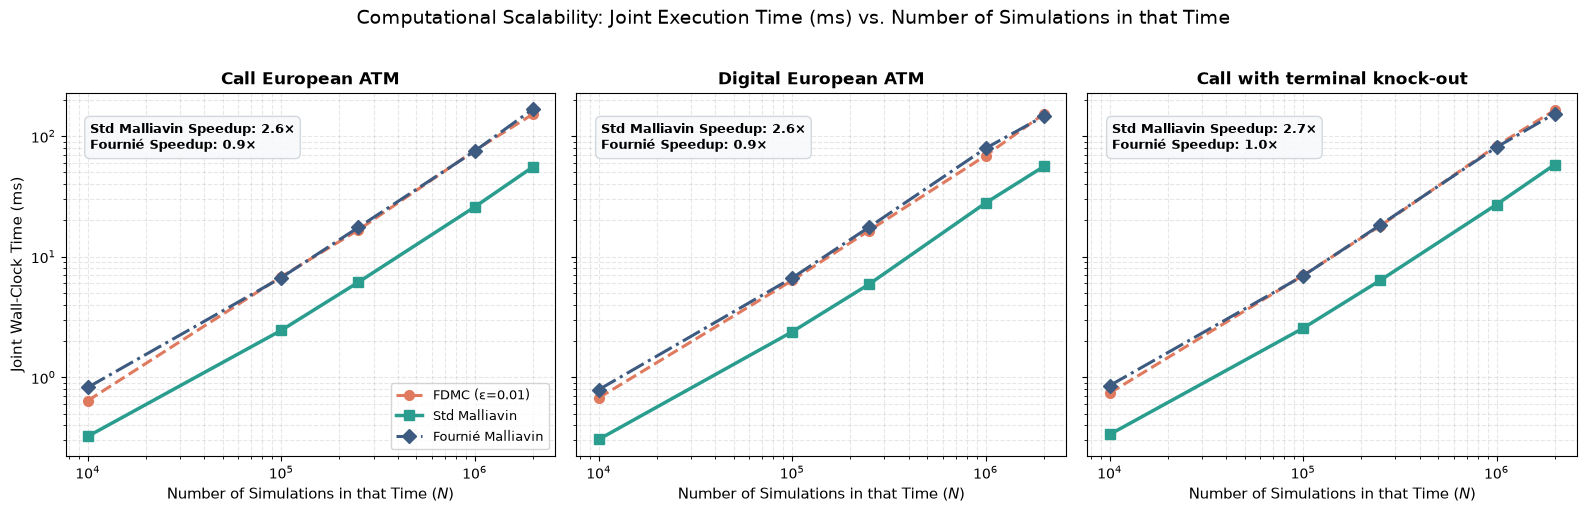

In [14]:
fig_runtime = utils.plot_runtime_vs_simulations(joint_timing_comp)
plt.show()

---
## 10. Summary

All statements below come from the per-path variances, biases and timings in Section 6 ($R = 100$ runs, $N = 10^6$, FDMC at $\varepsilon = 0.01$).

**Call (smooth, unbounded payoff)**
- Delta and Vega: FDMC is effectively the pathwise derivative and has the lowest variance. Standard Malliavin needs about $6\times$ (Delta) and $13\times$ (Vega) more paths; per path it is about $2.7\times$ cheaper, so about $2\times$ and $5\times$ more CPU time. Fournié is close to FDMC.
- Gamma: FDMC's per-path variance grows like $1/\varepsilon$. Standard Malliavin needs about $70\times$ fewer paths than FDMC, Fournié (general formula) about $7\times$ fewer again; the call-only shortcut a further $3.5\times$ fewer.

**Digital (jump)**
- FDMC Gamma is unusable at $\varepsilon = 0.01$ (per-path variance $\sim 10^4$, growing like $1/\varepsilon^3$); Delta needs about $10^3\times$ more paths than standard Malliavin.
- Standard Malliavin has the lowest variance for Delta and Gamma; Fournié has the lowest for Vega.

**Call with terminal knock-out**
- Standard Malliavin is the best choice for all three Greeks once cost per path is included.
- Fournié needs a cutoff with $\psi = 1$ and $\psi' = 0$ at both $K$ and $H$. With $\psi_K + \psi_H$ and a Gaussian cutoff the estimator is biased (Delta and Gamma even have the wrong sign).

**Bias of FDMC**: at $\varepsilon = 0.01$ the truncation bias is below the noise of $R = 100$ runs at $N = 10^6$ except for the knock-out Vega; at $\varepsilon = 0.1$ it is large for Vega. The main problem of FDMC on non-smooth payoffs is variance, not bias.